**Analisis Performa dan Deteksi Anomali Sistem IoT Multidomain**

In [6]:
# PySpark Core & MLlib
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

# Neo4j -> Graph Database
from neo4j import GraphDatabase

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import networkx as nx

from sklearn.ensemble import IsolationForest

Hadoop

In [7]:
HADOOP_NAMENODE = "hdfs://localhost:9000"

Untuk Buat SparkSession

In [8]:
spark = SparkSession.builder \
    .appName("Analisis Performa dan Deteksi Anomali Sistem IoT Multidomain") \
    .config("spark.hadoop.fs.defaultFS", HADOOP_NAMENODE) \
    .master("local[*]") \
    .getOrCreate()

Connect Neo4j

In [9]:
NEO4J_URI = "neo4j+ssc://170cef92.databases.neo4j.io"
NEO4J_USER = "170cef92"
NEO4J_PASSWORD = "3RVRmxn2_UhchjZ5pYkzxEnCffIs8bHmEniSd3mLA6A" 

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(query, parameters=None):
    with driver.session() as session:
        result = session.run(query, parameters or {})
        return [record for record in result]

In [ ]:
HDFS_DATA_PATH = "hdfs://localhost:9000/user/data/iot/data.csv"
LOCAL_DATA_PATH = "file:///C:/Users/Jase.LAPTOP-UM736EL9/Documents/Binus/S2/S3 P1/Code/backend/model/dataset/data.csv"

try:
    df = spark.read.csv(HDFS_DATA_PATH, header=True, inferSchema=True)
    print("Berhasil memuat data dari Hadoop HDFS!")
except Exception as e:
    print("Hadoop HDFS tidak aktif. Menggunakan fallback dataset lokal...")
    df = spark.read.csv(LOCAL_DATA_PATH, header=True, inferSchema=True)
    print(f"Berhasil memuat data lokal. Total baris: {df.count()}")

Hadoop HDFS tidak aktif. Menggunakan fallback dataset lokal...
Berhasil memuat data lokal. Total baris: 12000


In [11]:
# df = spark.read.csv(
#     r"C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset\data.csv",
#     header=True,
#     inferSchema=True
# )

In [12]:
df.printSchema()

root
 |-- Record_ID: string (nullable = true)
 |-- Timestamp: timestamp (nullable = true)
 |-- Domain_Type: string (nullable = true)
 |-- System_Region: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Sensor_Count: integer (nullable = true)
 |-- Data_Volume_MB: double (nullable = true)
 |-- Data_Velocity_RPS: double (nullable = true)
 |-- Data_Variety_Score: double (nullable = true)
 |-- Data_Veracity_Score: double (nullable = true)
 |-- CPU_Usage: double (nullable = true)
 |-- Memory_Usage: double (nullable = true)
 |-- System_Load: double (nullable = true)
 |-- Network_Latency_ms: double (nullable = true)
 |-- Packet_Loss_Rate: double (nullable = true)
 |-- Throughput_Mbps: double (nullable = true)
 |-- Temperature_C: double (nullable = true)
 |-- Vibration_Level: double (nullable = true)
 |-- Energy_Consumption_kWh: double (nullable = true)
 |-- Signal_Noise_Ratio: double (nullable = true)
 |-- Temporal_Variation: double (nullable = true)
 |-- Interaction_St

In [13]:
df.show(5)

+---------+-------------------+-----------------+-------------+------------+------------+--------------+-----------------+------------------+-------------------+---------+------------+-----------+------------------+----------------+---------------+-------------+---------------+----------------------+------------------+------------------+--------------------+--------------------+-----------------+--------------+------------------+---------------------+-----------------+------------------------+-------------+-----------------+-------------+
|Record_ID|          Timestamp|      Domain_Type|System_Region| Device_Type|Sensor_Count|Data_Volume_MB|Data_Velocity_RPS|Data_Variety_Score|Data_Veracity_Score|CPU_Usage|Memory_Usage|System_Load|Network_Latency_ms|Packet_Loss_Rate|Throughput_Mbps|Temperature_C|Vibration_Level|Energy_Consumption_kWh|Signal_Noise_Ratio|Temporal_Variation|Interaction_Strength|Nonlinear_Dependency|Uncertainty_Index|Decision_Score|Optimization_Score|Prediction_Confidence|

In [14]:
df.describe().show()

+-------+---------+-----------------+-------------+------------+------------------+-----------------+------------------+-------------------+-------------------+------------------+------------------+------------------+------------------+-------------------+------------------+-----------------+------------------+----------------------+------------------+-------------------+--------------------+--------------------+-------------------+-------------------+--------------------+---------------------+--------------------+------------------------+--------------------+-------------------+-------------+
|summary|Record_ID|      Domain_Type|System_Region| Device_Type|      Sensor_Count|   Data_Volume_MB| Data_Velocity_RPS| Data_Variety_Score|Data_Veracity_Score|         CPU_Usage|      Memory_Usage|       System_Load|Network_Latency_ms|   Packet_Loss_Rate|   Throughput_Mbps|    Temperature_C|   Vibration_Level|Energy_Consumption_kWh|Signal_Noise_Ratio| Temporal_Variation|Interaction_Strength|Nonl

In [15]:
df.groupBy("Domain_Type").count().orderBy("count", ascending=False).show()

+-----------------+-----+
|      Domain_Type|count|
+-----------------+-----+
|       Industrial| 3409|
|       Healthcare| 2412|
|          Finance| 2174|
|              IoT| 2003|
|Smart_Environment| 2002|
+-----------------+-----+



In [16]:
df.groupBy("System_Region").count().orderBy("count", ascending=False).show()

+-------------+-----+
|System_Region|count|
+-------------+-----+
|   South_Zone| 2429|
|    West_Zone| 2419|
| Central_Zone| 2410|
|   North_Zone| 2386|
|    East_Zone| 2356|
+-------------+-----+



In [17]:
df.groupBy("Device_Type").count().orderBy("count", ascending=False).show()

+------------+-----+
| Device_Type|count|
+------------+-----+
|Control_Unit| 2479|
| IoT_Gateway| 2407|
|  Sensor_Hub| 2394|
|Cloud_Server| 2366|
|   Edge_Node| 2354|
+------------+-----+



In [18]:
df.groupBy("Domain_Type").agg(
    F.round(F.avg("Data_Volume_MB"), 2).alias("Avg_Volume"),
    F.round(F.avg("Data_Velocity_RPS"), 2).alias("Avg_Velocity"),
    F.round(F.avg("Data_Variety_Score"), 2).alias("Avg_Variety"),
    F.round(F.avg("Data_Veracity_Score"), 2).alias("Avg_Veracity")
).orderBy("Domain_Type").show()

+-----------------+----------+------------+-----------+------------+
|      Domain_Type|Avg_Volume|Avg_Velocity|Avg_Variety|Avg_Veracity|
+-----------------+----------+------------+-----------+------------+
|          Finance|   2126.36|     1092.06|       0.59|        0.71|
|       Healthcare|   2162.72|     1103.04|        0.6|        0.72|
|       Industrial|   2162.02|     1095.48|        0.6|        0.72|
|              IoT|   2138.99|     1093.39|       0.59|        0.72|
|Smart_Environment|   2175.76|     1101.01|       0.59|        0.72|
+-----------------+----------+------------+-----------+------------+



In [19]:
pdf = df.toPandas()

c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_31888\2759846860.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")


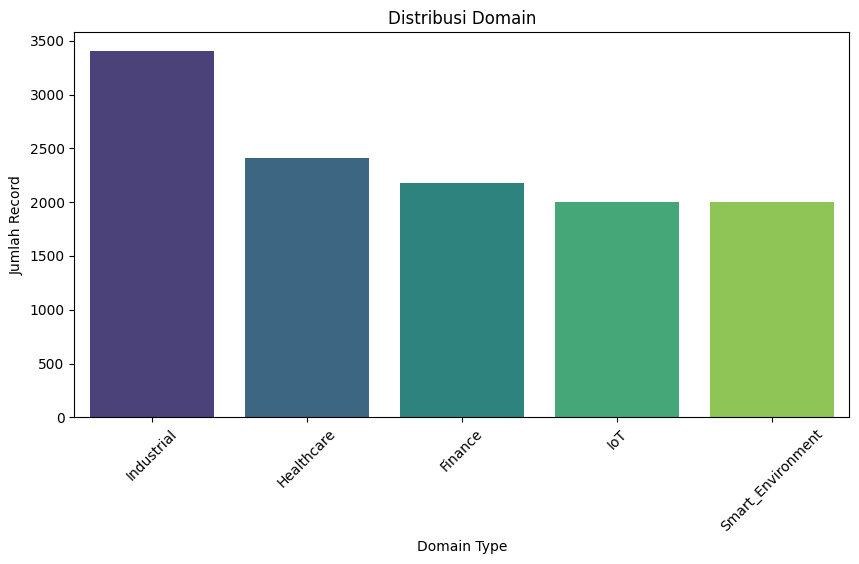

In [20]:
plt.figure(figsize=(10, 5))
domain_counts = pdf["Domain_Type"].value_counts()
sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")
plt.title("Distribusi Domain")
plt.xlabel("Domain Type")
plt.ylabel("Jumlah Record")
plt.xticks(rotation=45)
plt.savefig("domain_distribution.png", dpi=150)
plt.show()

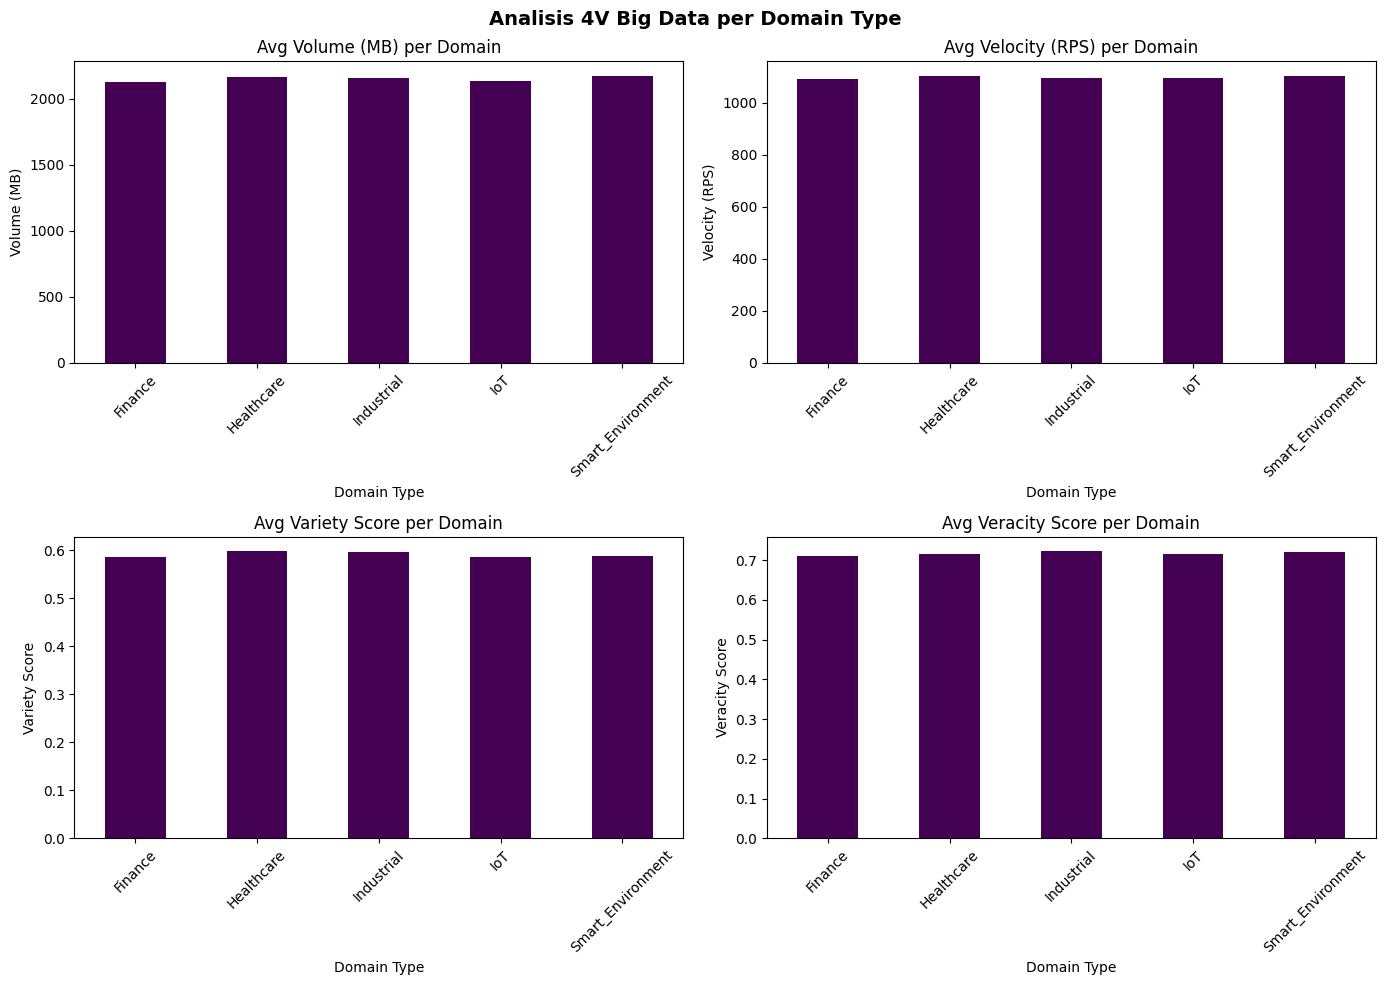

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ["Data_Volume_MB", "Data_Velocity_RPS", "Data_Variety_Score", "Data_Veracity_Score"]
titles = ["Volume (MB)", "Velocity (RPS)", "Variety Score", "Veracity Score"]

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    pdf.groupby("Domain_Type")[metric].mean().plot(kind="bar", ax=ax, colormap="viridis")
    ax.set_title(f"Avg {title} per Domain")
    ax.set_xlabel("Domain Type")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Analisis 4V Big Data per Domain Type", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("4v_analysis.png", dpi=150)
plt.show()

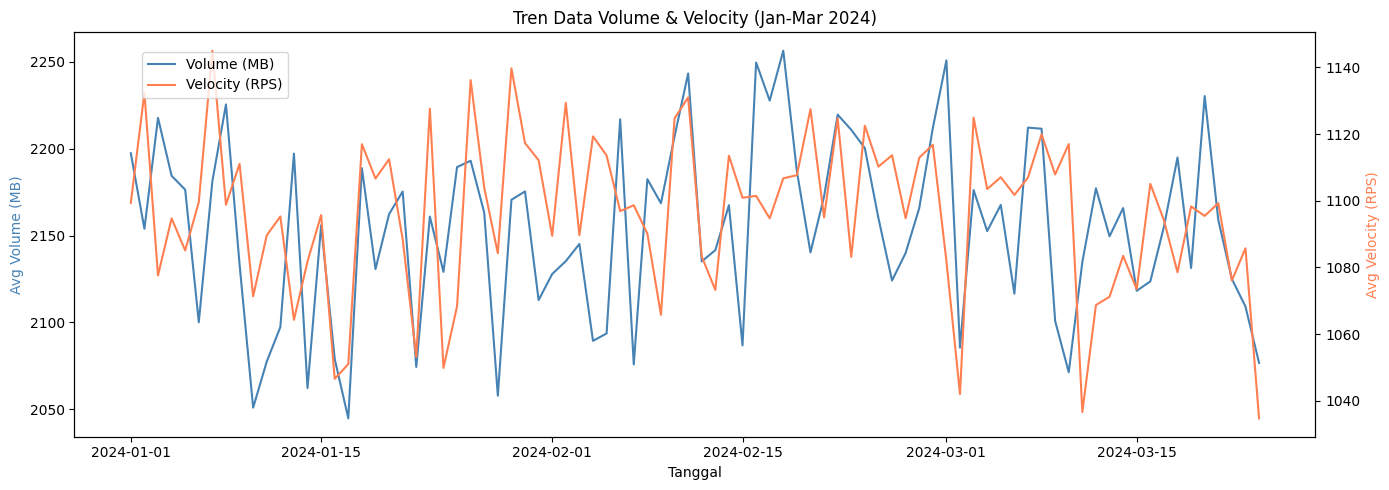

In [22]:
pdf["Timestamp"] = pd.to_datetime(pdf["Timestamp"])
pdf_time = pdf.groupby(pdf["Timestamp"].dt.date).agg({
    "Data_Volume_MB": "mean",
    "Data_Velocity_RPS": "mean"
}).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(pdf_time["Timestamp"], pdf_time["Data_Volume_MB"], color="steelblue", label="Volume (MB)")
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Avg Volume (MB)", color="steelblue")

ax2 = ax1.twinx()
ax2.plot(pdf_time["Timestamp"], pdf_time["Data_Velocity_RPS"], color="coral", label="Velocity (RPS)")
ax2.set_ylabel("Avg Velocity (RPS)", color="coral")

plt.title("Tren Data Volume & Velocity (Jan-Mar 2024)")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.savefig("trend_analysis.png", dpi=150)
plt.show()

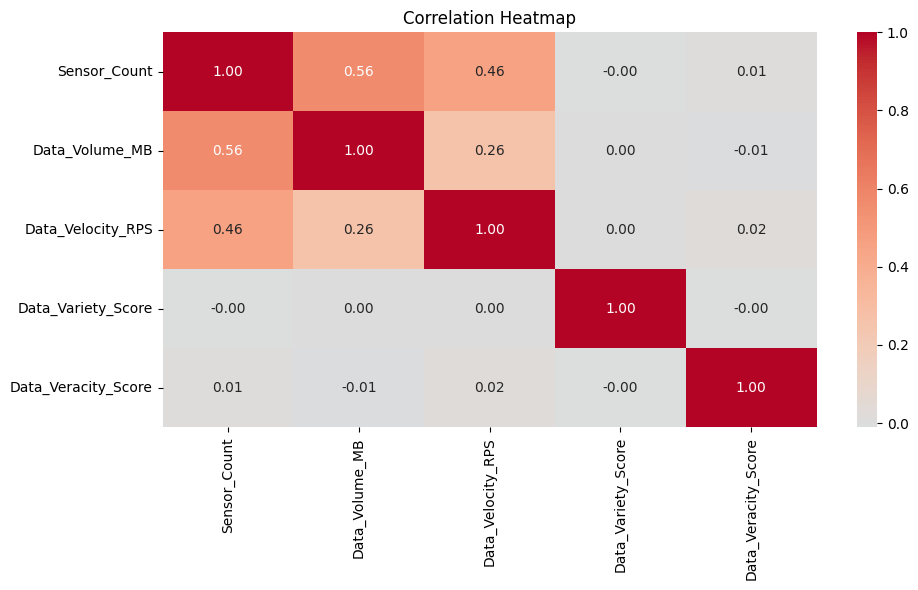

In [23]:
plt.figure(figsize=(10, 6))
numeric_cols = ["Sensor_Count", "Data_Volume_MB", "Data_Velocity_RPS", 
                "Data_Variety_Score", "Data_Veracity_Score"]
corr_matrix = pdf[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

In [24]:
feature_cols = ["Sensor_Count", "Data_Volume_MB", "Data_Velocity_RPS", "Data_Variety_Score", "Data_Veracity_Score"]

In [25]:
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
df_assembled = assembler.transform(df)

In [26]:
df_assembled.show(5)

+---------+-------------------+-----------------+-------------+------------+------------+--------------+-----------------+------------------+-------------------+---------+------------+-----------+------------------+----------------+---------------+-------------+---------------+----------------------+------------------+------------------+--------------------+--------------------+-----------------+--------------+------------------+---------------------+-----------------+------------------------+-------------+-----------------+-------------+--------------------+
|Record_ID|          Timestamp|      Domain_Type|System_Region| Device_Type|Sensor_Count|Data_Volume_MB|Data_Velocity_RPS|Data_Variety_Score|Data_Veracity_Score|CPU_Usage|Memory_Usage|System_Load|Network_Latency_ms|Packet_Loss_Rate|Throughput_Mbps|Temperature_C|Vibration_Level|Energy_Consumption_kWh|Signal_Noise_Ratio|Temporal_Variation|Interaction_Strength|Nonlinear_Dependency|Uncertainty_Index|Decision_Score|Optimization_Score|P

In [27]:
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled)

In [28]:
df_scaled.show(5)

+---------+-------------------+-----------------+-------------+------------+------------+--------------+-----------------+------------------+-------------------+---------+------------+-----------+------------------+----------------+---------------+-------------+---------------+----------------------+------------------+------------------+--------------------+--------------------+-----------------+--------------+------------------+---------------------+-----------------+------------------------+-------------+-----------------+-------------+--------------------+--------------------+
|Record_ID|          Timestamp|      Domain_Type|System_Region| Device_Type|Sensor_Count|Data_Volume_MB|Data_Velocity_RPS|Data_Variety_Score|Data_Veracity_Score|CPU_Usage|Memory_Usage|System_Load|Network_Latency_ms|Packet_Loss_Rate|Throughput_Mbps|Temperature_C|Vibration_Level|Energy_Consumption_kWh|Signal_Noise_Ratio|Temporal_Variation|Interaction_Strength|Nonlinear_Dependency|Uncertainty_Index|Decision_Score

In [29]:
inertia = []
k_values = range(2, 8)

In [30]:
for k in k_values:
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)
    model = kmeans.fit(df_scaled)
    cost = model.summary.trainingCost
    inertia.append(cost)
    print(f"K->{k}, Inertia->{cost:.2f}")

K->2, Inertia->44369.46
K->3, Inertia->39196.21
K->4, Inertia->35611.94
K->5, Inertia->32177.59
K->6, Inertia->29799.47
K->7, Inertia->27833.70


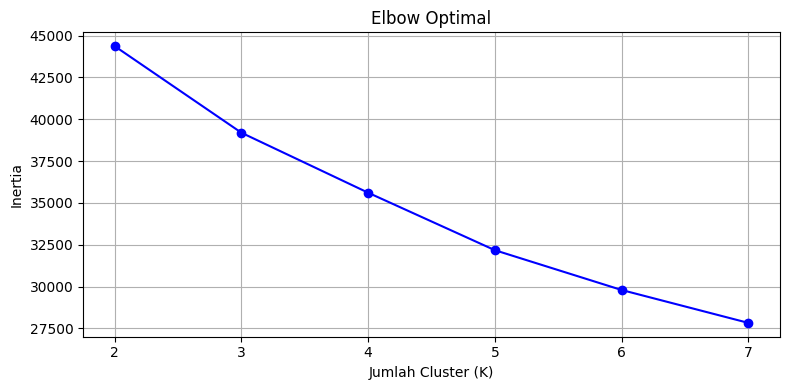

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertia, 'bo-')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.title('Elbow Optimal')
plt.tight_layout()
plt.grid(True)
plt.savefig('elbow_method.png', dpi=150)
plt.show()

In [32]:
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=3, seed=42)
model = kmeans.fit(df_scaled)

In [33]:
df_clustered = model.transform(df_scaled)

In [34]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette = eval.evaluate(df_clustered)
print(f"Silhouette Score: {silhouette:.4f}")

Silhouette Score: 0.3129


In [35]:
df_clustered.groupBy("cluster").agg(
    F.count("*").alias("Jumlah"),
    F.round(F.avg("Data_Volume_MB"), 2).alias("Avg_Volume"),
    F.round(F.avg("Data_Velocity_RPS"), 2).alias("Avg_Velocity"),
    F.round(F.avg("Data_Variety_Score"), 2).alias("Avg_Variety"),
    F.round(F.avg("Data_Veracity_Score"), 2).alias("Avg_Veracity")
).orderBy("cluster").show()

+-------+------+----------+------------+-----------+------------+
|cluster|Jumlah|Avg_Volume|Avg_Velocity|Avg_Variety|Avg_Veracity|
+-------+------+----------+------------+-----------+------------+
|      0|  4888|   2612.74|     1285.57|       0.59|        0.72|
|      1|  3563|   1856.48|      958.45|       0.58|        0.58|
|      2|  3549|   1821.37|      976.23|       0.61|        0.86|
+-------+------+----------+------------+-----------+------------+



In [36]:
pdf_clustered = df_clustered.select(
    "Data_Volume_MB", "Data_Velocity_RPS", "Data_Variety_Score", 
    "Data_Veracity_Score", "Domain_Type", "cluster"
).toPandas()

c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


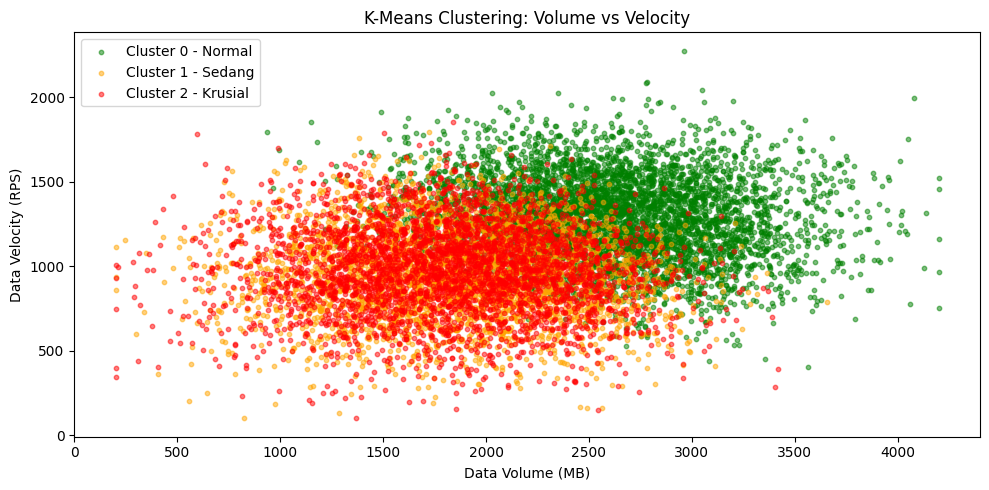

In [37]:
plt.figure(figsize=(10, 5))
colors = {0: "green", 1: "orange", 2: "red"}
labels = {0: "Cluster 0 - Normal", 1: "Cluster 1 - Sedang", 2: "Cluster 2 - Krusial"}

for cluster_id in sorted(pdf_clustered["cluster"].unique()):
    subset = pdf_clustered[pdf_clustered["cluster"] == cluster_id]
    plt.scatter(subset["Data_Volume_MB"], subset["Data_Velocity_RPS"],
                c=colors[cluster_id], label=labels[cluster_id], alpha=0.5, s=10)

plt.xlabel("Data Volume (MB)")
plt.ylabel("Data Velocity (RPS)")
plt.title("K-Means Clustering: Volume vs Velocity")
plt.legend()
plt.tight_layout()
plt.savefig("kmeans_clustering.png", dpi=150)
plt.show()

In [38]:
pdf_graph = df.select("Device_Type", "System_Region", "Domain_Type", "Data_Volume_MB", "Data_Velocity_RPS").toPandas()

c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


In [39]:
run_query("MATCH (n) DETACH DELETE n")
run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (d:Device) REQUIRE d.name IS UNIQUE")
run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (r:Region) REQUIRE r.name IS UNIQUE")
run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (dom:Domain) REQUIRE dom.name IS UNIQUE")
print("Instance Neo4j berhasil dibersihkan dan siap menerima data!")

Instance Neo4j berhasil dibersihkan dan siap menerima data!


In [40]:
# G = nx.DiGraph()

In [41]:
device = pdf_graph.groupby(["Device_Type", "System_Region"]).agg(
    weight=("Data_Volume_MB", "mean"),
    velocity=("Data_Velocity_RPS", "mean")
).reset_index()

domain = pdf_graph.groupby(["System_Region", "Domain_Type"]).agg(
    weight=("Data_Volume_MB", "mean"),
    velocity=("Data_Velocity_RPS", "mean")
).reset_index()

In [42]:
for _, row in device.iterrows():
    cypher = """
    MERGE (d:Device {name: $device})
    MERGE (r:Region {name: $region})
    MERGE (d)-[rel:ROUTES_TO]->(r)
    SET rel.weight = $weight, rel.velocity = $velocity
    """
    run_query(cypher, {
        "device": str(row["Device_Type"]),
        "region": str(row["System_Region"]),
        "weight": float(round(row["weight"], 2)),
        "velocity": float(round(row["velocity"], 2))
    })

In [43]:
for _, row in domain.iterrows():
    cypher = """
    MERGE (r:Region {name: $region})
    MERGE (dom:Domain {name: $domain})
    MERGE (r)-[rel:SERVES]->(dom)
    SET rel.weight = $weight, rel.velocity = $velocity
    """
    run_query(cypher, {
        "region": str(row["System_Region"]),
        "domain": str(row["Domain_Type"]),
        "weight": float(round(row["weight"], 2)),
        "velocity": float(round(row["velocity"], 2))
    })

In [44]:
count_nodes = run_query("MATCH (n) RETURN count(n) AS total_nodes")[0]["total_nodes"]
count_edges = run_query("MATCH ()-[r]->() RETURN count(r) AS total_edges")[0]["total_edges"]

In [45]:
print("Nodes di Neo4j -> ", count_nodes)
print("Edges di Neo4j -> ", count_edges)

Nodes di Neo4j ->  15
Edges di Neo4j ->  50


In [46]:
degree_query = """
MATCH (n)
OPTIONAL MATCH (n)-[r]-()
RETURN n.name AS node, count(r) * 1.0 AS degree
ORDER BY degree DESC
"""
degree_res = run_query(degree_query)
max_deg = (count_nodes - 1) if count_nodes > 1 else 1.0
degree_cent = {r["node"]: r["degree"] / max_deg for r in degree_res}

In [47]:
try:
    run_query("""
    CALL gds.graph.project.cypher(
        'iotGraph',
        'MATCH (n) RETURN id(n) AS id, labels(n) AS labels',
        'MATCH (s)-[r]->(t) RETURN id(s) AS source, id(t) AS target, type(r) AS type, r.weight AS weight'
    )
    """)

    pr_records = run_query("CALL gds.pageRank.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    pagerank = {r["node"]: r["score"] for r in pr_records}
    
    bw_records = run_query("CALL gds.betweenness.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    betweenness_cent = {r["node"]: r["score"] for r in bw_records}
    print("Graph Analytics berhasil dihitung menggunakan Neo4j GDS Plugin!")
except Exception:
    bw_query = """
    MATCH (n)
    OPTIONAL MATCH p = allShortestPaths((a)-[*]->(b))
    WHERE a <> b AND a <> n AND b <> n AND n IN nodes(p)
    RETURN n.name AS node, count(p) * 1.0 AS score
    """
    bw_res = run_query(bw_query)
    bw_dict = {r["node"]: r["score"] for r in bw_res}
    max_bw = max(bw_dict.values()) if bw_dict and max(bw_dict.values()) > 0 else 1.0
    betweenness_cent = {k: v / max_bw for k, v in bw_dict.items()}
    pr_query = """
    MATCH (n)
    OPTIONAL MATCH (in)-[r]->(n)
    RETURN n.name AS node, coalesce(sum(r.weight), 1.0) / 10000.0 AS score
    """
    pr_res = run_query(pr_query)
    pagerank = {r["node"]: r["score"] for r in pr_res}

In [48]:
for node, score in sorted(degree_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Central_Zone: 0.7143
East_Zone: 0.7143
North_Zone: 0.7143
South_Zone: 0.7143
West_Zone: 0.7143
Cloud_Server: 0.3571
Control_Unit: 0.3571
Edge_Node: 0.3571
IoT_Gateway: 0.3571
Sensor_Hub: 0.3571
Finance: 0.3571
Healthcare: 0.3571
Industrial: 0.3571
IoT: 0.3571
Smart_Environment: 0.3571


In [49]:
for node, score in sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Central_Zone: 1.0000
East_Zone: 1.0000
North_Zone: 1.0000
South_Zone: 1.0000
West_Zone: 1.0000
Cloud_Server: 0.0000
Control_Unit: 0.0000
Edge_Node: 0.0000
IoT_Gateway: 0.0000
Sensor_Hub: 0.0000
Finance: 0.0000
Healthcare: 0.0000
Industrial: 0.0000
IoT: 0.0000
Smart_Environment: 0.0000


In [50]:
for node, score in sorted(pagerank.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Smart_Environment: 1.0878
North_Zone: 1.0861
Central_Zone: 1.0814
Healthcare: 1.0810
Industrial: 1.0810
South_Zone: 1.0784
West_Zone: 1.0758
IoT: 1.0693
East_Zone: 1.0630
Finance: 1.0624
Cloud_Server: 0.0000
Control_Unit: 0.0000
Edge_Node: 0.0000
IoT_Gateway: 0.0000
Sensor_Hub: 0.0000


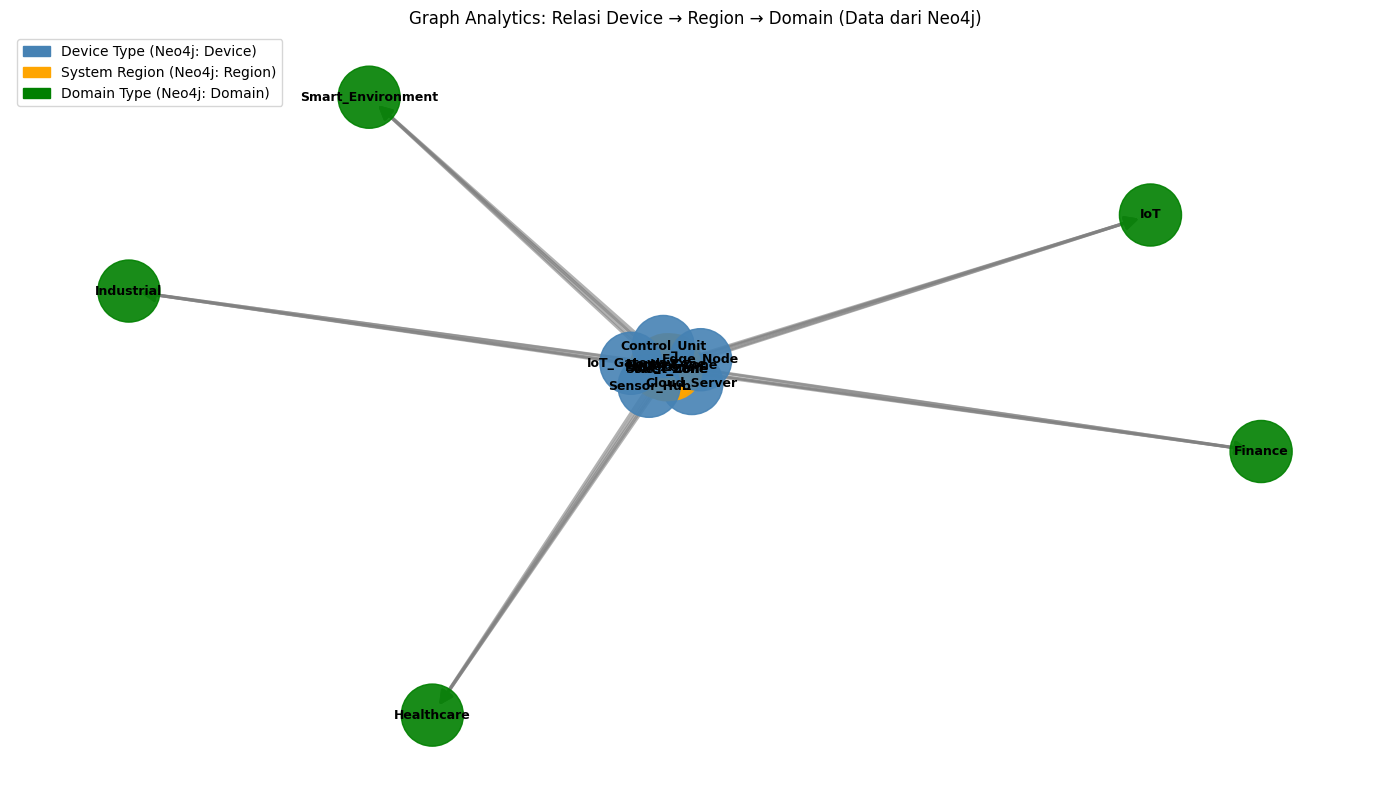

In [51]:
edges_data = run_query("""
MATCH (a)-[r]->(b)
RETURN a.name AS source, labels(a)[0] AS source_label, 
       b.name AS target, labels(b)[0] AS target_label, 
       r.weight AS weight
""")
G = nx.DiGraph()
for edge in edges_data:
    G.add_edge(edge["source"], edge["target"], weight=edge["weight"])
plt.figure(figsize=(14, 8))
color_map = []
for node in G.nodes():
    if node in pdf_graph["Device_Type"].values:
        color_map.append("steelblue")
    elif node in pdf_graph["System_Region"].values:
        color_map.append("orange")
    else:
        color_map.append("green")
pos = nx.spring_layout(G, seed=42, k=2)
weights = [G[u][v]["weight"] / 1000 for u, v in G.edges()]
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=2000, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.6, arrows=True, arrowsize=20, edge_color="gray")
legend = [
    Patch(color="steelblue", label="Device Type (Neo4j: Device)"),
    Patch(color="orange", label="System Region (Neo4j: Region)"),
    Patch(color="green", label="Domain Type (Neo4j: Domain)")
]
plt.legend(handles=legend, loc="upper left")
plt.title("Graph Analytics: Relasi Device → Region → Domain (Data dari Neo4j)")
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_analytics.png", dpi=150)
plt.show()

In [52]:
top_node = max(betweenness_cent, key=betweenness_cent.get)
print(f"Node paling kritis (Jalur Penghubung Utama): {top_node}")
print(f"Betweenness Centrality: {betweenness_cent[top_node]:.4f}")
print(f"PageRank: {pagerank[top_node]:.4f}")

Node paling kritis (Jalur Penghubung Utama): Central_Zone
Betweenness Centrality: 1.0000
PageRank: 1.0814


In [53]:
cent_df = pd.DataFrame({
    "Node": list(degree_cent.keys()),
    "Degree": [degree_cent.get(k, 0) for k in degree_cent.keys()],
    "Betweenness": [betweenness_cent.get(k, 0) for k in degree_cent.keys()],
    "PageRank": [pagerank.get(k, 0) for k in degree_cent.keys()]
}).sort_values("Betweenness", ascending=False)
cent_df.head(10)

,Node,Degree,Betweenness,PageRank
0,Central_Zone,0.714286,1.0,1.081429
1,East_Zone,0.714286,1.0,1.062985
2,North_Zone,0.714286,1.0,1.086107
3,South_Zone,0.714286,1.0,1.078379
4,West_Zone,0.714286,1.0,1.075751
5,Cloud_Server,0.357143,0.0,0.000000
6,Control_Unit,0.357143,0.0,0.000000
7,Edge_Node,0.357143,0.0,0.000000
8,IoT_Gateway,0.357143,0.0,0.000000
9,Sensor_Hub,0.357143,0.0,0.000000


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_31888\3400271322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cent_df, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_31888\3400271322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cent_df, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_31888\3400271322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cent_df, x="Node", y=metric, palette="

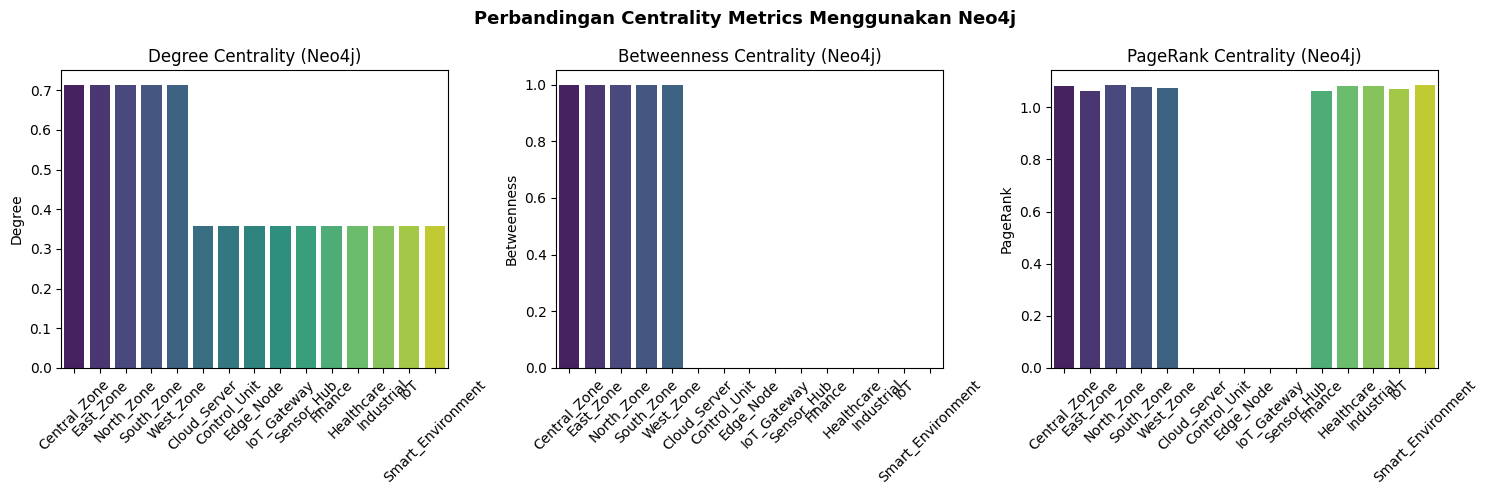

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ["Degree", "Betweenness", "PageRank"]

for ax, metric in zip(axes, metrics):
    sns.barplot(data=cent_df, x="Node", y=metric, palette="viridis", ax=ax)
    ax.set_title(f"{metric} Centrality (Neo4j)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Perbandingan Centrality Metrics Menggunakan Neo4j", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("centrality_analysis.png", dpi=150)
plt.show()

In [55]:
from sklearn.ensemble import IsolationForest

In [56]:
# Anomaly Detection
feature_cols = ["Sensor_Count", "Data_Volume_MB", "Data_Velocity_RPS", "Data_Variety_Score", "Data_Veracity_Score"]

In [57]:
pdf_ml = df.select(feature_cols + ["Domain_Type", "System_Region"]).toPandas()

c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


In [58]:
iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)

In [59]:
pdf_ml["anomaly"] = iso.fit_predict(pdf_ml[feature_cols])
pdf_ml["anomaly_label"] = pdf_ml["anomaly"].map({1: "Normal", -1: "Anomali"})

In [60]:
iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)

In [61]:
print(pdf_ml['anomaly_label'].value_counts())

anomaly_label
Normal     11400
Anomali      600
Name: count, dtype: int64


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_31888\1833228171.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=anomaly_domain.index, y=anomaly_domain.values, palette="Reds_r", ax=axes[1])


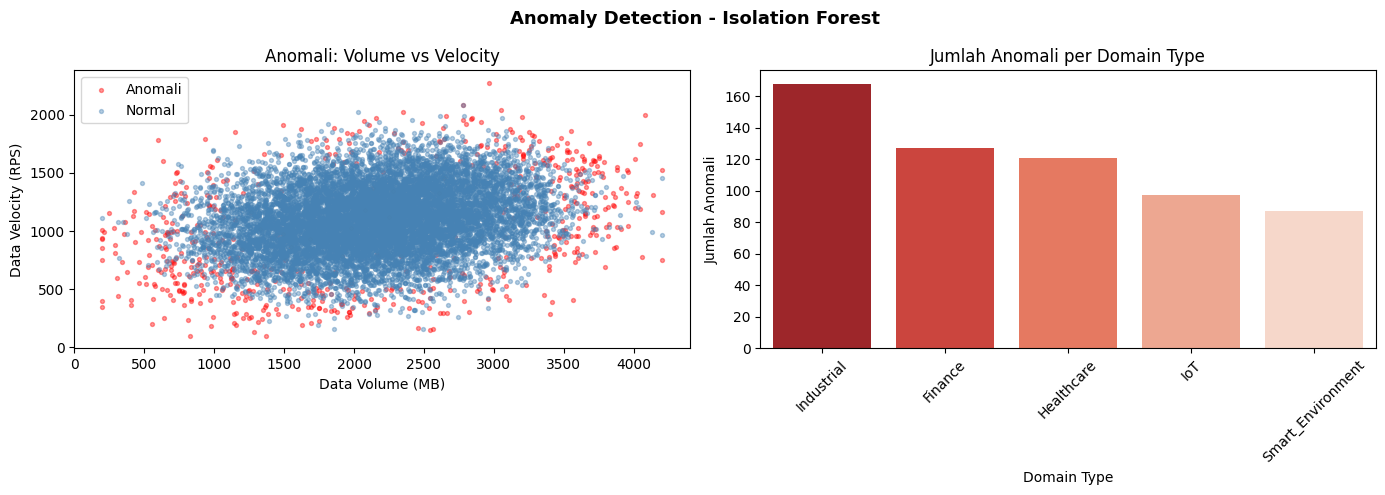

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scatter plot Volume vs Velocity
for label, group in pdf_ml.groupby("anomaly_label"):
    axes[0].scatter(group["Data_Volume_MB"], group["Data_Velocity_RPS"],
                    label=label, alpha=0.4, s=8,
                    color="red" if label == "Anomali" else "steelblue")
axes[0].set_xlabel("Data Volume (MB)")
axes[0].set_ylabel("Data Velocity (RPS)")
axes[0].set_title("Anomali: Volume vs Velocity")
axes[0].legend()

# Plot 2: Distribusi Anomali per Domain Type
anomaly_domain = pdf_ml[pdf_ml["anomaly_label"] == "Anomali"]["Domain_Type"].value_counts()
sns.barplot(x=anomaly_domain.index, y=anomaly_domain.values, palette="Reds_r", ax=axes[1])
axes[1].set_title("Jumlah Anomali per Domain Type")
axes[1].set_xlabel("Domain Type")
axes[1].set_ylabel("Jumlah Anomali")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Anomaly Detection - Isolation Forest", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("anomaly_detection.png", dpi=150)
plt.show()


In [63]:
# ===================================================
# INSPEKSI HADOOP FILESYSTEM OBJECT
# ===================================================
conf = spark.sparkContext._jsc.hadoopConfiguration()
fs = spark.sparkContext._gateway.jvm.org.apache.hadoop.fs.FileSystem.get(conf)

print("Hadoop FileSystem Class :", fs.getClass().getName())
print("Hadoop URI Scheme       :", fs.getScheme())
print("Hadoop Working Directory:", str(fs.getWorkingDirectory()))
print("Hadoop Home Directory   :", str(fs.getHomeDirectory()))


Hadoop FileSystem Class : org.apache.hadoop.hdfs.DistributedFileSystem
Hadoop URI Scheme       : hdfs
Hadoop Working Directory: hdfs://localhost:9000/user/Jase
Hadoop Home Directory   : hdfs://localhost:9000/user/Jase


In [ ]:
import os
import shutil

OUTPUT_FILE = "hadoop_clustered_output.parquet"

if os.path.exists(OUTPUT_FILE):
    if os.path.isdir(OUTPUT_FILE):
        shutil.rmtree(OUTPUT_FILE)
    else:
        os.remove(OUTPUT_FILE)

df_export = df_clustered.select("Record_ID", "Domain_Type", "System_Region", "cluster").toPandas()
df_export.to_parquet(OUTPUT_FILE, compression="snappy", index=False)

print("Data berhasil disimpan dalam format Hadoop Parquet (Snappy)!")
print(f"Total baris tersimpan : {len(df_export)}")
print(f"Ukuran file Parquet   : {os.path.getsize(OUTPUT_FILE) / 1024:.2f} KB")

Data berhasil disimpan dalam format Hadoop Parquet (Snappy)!
Total baris tersimpan : 12000
Ukuran file Parquet   : 85.90 KB


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
